# E126: does a teacher-trained copy land in the same place when only its batch order changes?

## The answer

Mostly yes, but not for the one copy that stopped the earlier run. That copy, the emoticon task's Pile-text copy of
the Adam fine-tune, moved by 0.135 in target probability across three batch orders on the L40. That is four times
the spread its two orders showed on the H100. At every order it reached under 40% of its teacher's gain, so it
carries no reading of where its gain sits. The three copies the earlier run placed in the re-switching corner stayed
there at both new orders.


## What we were trying to test

**Teacher training** copies a fine-tuned model, the teacher, into the decomposition. Only the subcomponents' U and V
train, for 1,000 steps, on the KL divergence from the teacher, with Γ and Δ frozen. The **Pile-text copy** trains on
Pile text that never shows the task. The order in which those Pile rows are batched is set by one seed, the
**batch order**.

The teacher-route-split run regenerated twelve such copies on an L40 card. One of them, the emoticon task's Pile-text
copy of the Adam fine-tune, reached a held-out probability of the target token of 0.744. The original teacher-training
run had read 0.902 for the same copy on an H100. That run's fourth amendment had rerun the copy at a second batch
order on the H100 and read 0.934, a change of 0.032. The 0.158 shortfall stopped the regeneration run by its rule.

This run rebuilds that copy on the L40 at batch orders 0, 1 and 2, with everything else as the regeneration run had
it. Order 0 is the control: it must reproduce 0.744, or the job stops. It also rebuilds, at orders 1 and 2, the three
Pile-text copies the regeneration run placed in the re-switching corner. Those are both copies on the first key-rule
task and the SGD copy on the second.

Each copy's gain at the trigger is split two ways, as in the regeneration run:

- the **re-switching share** $r$: the share of the gain that comes from Γ's new masks alone, with the original
  subcomponents. 0 means the masks change nothing; 1 means switching carries the whole gain.
- the **masked-off share**: the share carried by the change in what the subcomponents Γ keeps off contribute. 0 means
  none of the gain; 1 means all of it.

A copy is **re-switching** if $r$ is at least 0.6 and its masked-off share at most 0.25. It is **unreadable** if its
gain is under half its teacher's. These lines are frozen from the copy-versus-map experiment.


## What we expected, and why

- **The low emoticon copy is an unlucky batch order**, with medium confidence. On the L40 the emoticon teachers, both
  emoticon task-text copies and the emoticon SGD Pile-text copy all reproduced the H100 within 0.002. So the card does
  not move this recipe in general. We expected orders 1 and 2 to read about 0.90 to 0.93, both above 0.852. Both
  under 0.794 would have meant a card difference; anything else, unstable.
- **The re-switching corner holds at new orders**, two of three cells. The r0 SGD copy sat well inside both lines.
  The r0 Adam copy reached only 0.58 of its teacher's gain, close to the readability line. The r1 SGD copy's
  masked-off share was 0.237, just under the 0.25 line, so we called it a coin flip.


## Does batch order alone move the emoticon Adam Pile-text copy?

The left panel plots the copy's held-out target probability at each batch order. Green squares are the L40 copies,
open diamonds the H100 copies, and the grey band the H100's range over its two orders. The dashed lines are the two
filed bars. The right panel is read in the next section.


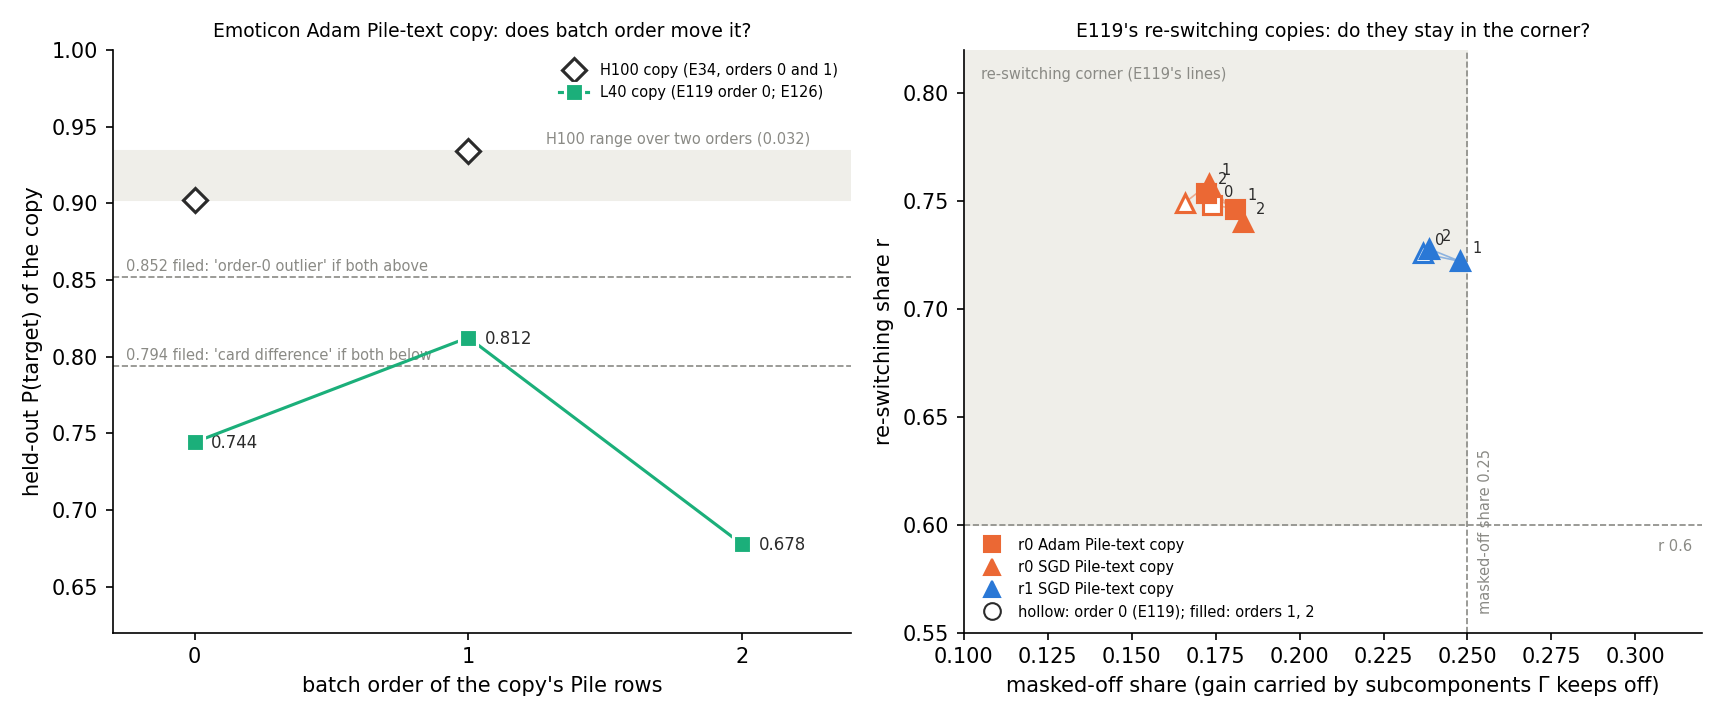

In [1]:
from IPython.display import Image

Image("../experiments/copy_reproducibility/figures/orders.png", width=1000)


**Reading it.** Yes: batch order alone moves this copy, and by far more than on the H100. Order 0 reproduced the
regeneration run's 0.744 exactly, so the apparatus is the same. Orders 1 and 2 read 0.812 and 0.678, a spread of
0.135 over the three orders. The H100's two orders differed by 0.032. One new order landed above the card-difference
bar and one below it, so the filed rule reads unstable. No L40 order came within 0.09 of either H100 value, though.
With two H100 orders and three L40 orders, a lower level on this card and a larger order effect cannot be told apart.

The copy is also unreadable at every order. It reached 0.36, 0.38 and 0.34 of its teacher's gain, under the 0.5
line. So the regeneration run's stop was this one cell moving with batch order on the L40. The same code reproduced
the other eleven copies within 0.016 and this one exactly at order 0, so a code fault is unlikely.


## Do the three re-switching copies stay in the corner at new batch orders?

**Reading it.** Yes, all three, at both new orders. The right panel of the figure above plots each copy's masked-off
share against its re-switching share. Hollow marks are order 0, from the regeneration run, and filled marks orders 1
and 2. Every point stays in the shaded corner. The re-switching share stayed between 0.72 and 0.76. No re-switching
share moved by more than 0.01 from its order-0 value, and no masked-off share by more than 0.02.

The r1 SGD copy stays closest to the edge. Its masked-off share read 0.248 and 0.239 at the new orders, against the
0.25 line. The two r0 copies sit at 0.17 to 0.18, well inside. Every copy kept over 0.6 of its teacher's gain, so all
six new readings are readable.


## What we learned

The regeneration run's stop came from one copy that is sensitive to batch order on the L40, and that copy carries no
reading of where its gain sits at any order. The three placements in the re-switching corner do not depend on batch
order, so the regeneration run's finding that some Pile-text copies land in the re-switching corner stands for
orders 0 to 2 on this card. For the original teacher-training results, the emoticon Adam Pile-text copy's target
probability now carries a spread of 0.135, not 0.032. Task-text copies remain the method to cite.

## How compelling is the evidence

Three orders for the emoticon cell and two new orders for each corner cell, on one card and one teacher seed. The
filed noise floor for the shares, from a second order in the copy-versus-map experiment, was 0.0004 in $r$. Here the
shares moved by up to 0.017, still far from the lines except for the r1 SGD masked-off share. The order-0 control
matched to the last digit, and the four regenerated teachers matched the regeneration run exactly.

## Surprises

The emoticon copy did not return to the H100's level at any order, against the expectation of about 0.90 to 0.93.
Its spread over three orders, 0.135, is four times the largest order change the original run saw on any copy.

## What next

- Run the emoticon Adam Pile-text copy on the H100 at orders 1 and 2. If those read near 0.90, the card lowers this
  copy; if they spread like the L40's, the cell is order-sensitive on both cards.
- Nothing is needed for the corner readings: they held at every order.


## Scorecard

Scored by the filed rules in `experiments/copy_reproducibility/results/predictions.json`; nothing refiled. Full
tables in `reports/analyses/2026-11-06_analysis_e126-copy-reproducibility.md`.

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| C0 | teachers regenerate | each within 0.005 of E119 | all four differ by 0 | pass |
| C1 | order-0 control | P within 0.005 of 0.744 | 0.744, difference 0 | pass |
| P1 | emoticon Adam copy: order-0 outlier | orders 1, 2 both ≥ 0.852 | 0.812, 0.678; spread 0.135 | **unstable** (expected outlier) |
| P2 | corner holds, expected 2 of 3 | orders 1, 2 both re-switching | 3 of 3 hold | holds 3 of 3 |

## Departures from the literature

None. The copy recipe, the route split and the labelling lines are the regeneration run's, unchanged; only the
batch-order seed differs.

## Not run

- The H100 at orders 1 and 2 for any cell, so card and order are not fully separated for the emoticon copy.
- Orders past 2; a second teacher seed; the task-text copies at new orders.
- The route split of the emoticon copy on the H100, so whether the original 0.902 copy was readable is unknown.

## Provenance

`experiments/copy_reproducibility/results/copy_reproducibility.json`; MATS cluster `debug` QoS, NVIDIA L40, jobs
54763 and 54772 on 2026-11-06, 19:34 to 20:13 with the restart, $0. Code `experiments/copy_reproducibility/run.py`; results
commit 90716439. Offsets and `run.log` in `results/large/`.
